# Étape E : méthode de fouille et étude d'ablation

**Problématique :** le texte des avis permet-il de prédire si un logement est bien ou moins bien noté
sur la propreté, l'emplacement et le rapport qualité-prix ? Quels prétraitements linguistiques
rendent cette prédiction plus fiable ?

On part de la table finale `logements.parquet` (étape D) : une ligne par logement.
Les fonctions sont dans `src/fouille.py`.

Plan :
1. Les données
2. Ce qu'on veut prédire : les étiquettes `y`
3. Comparaison des modèles
4. Étude d'ablation : apport de chaque prétraitement
5. Évaluation détaillée sur un jeu de test
6. Mots les plus associés à chaque classe
7. Sauvegarde des résultats

In [17]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

sys.path.append('../src')
import fouille as fo

pd.set_option('display.max_colwidth', 150)

## 1. Les données

Une ligne par logement : le nombre d'avis, les versions du texte (avis mis bout à bout) et les notes.

In [2]:
logements = pd.read_parquet('../data/processed/logements.parquet')
print(logements.shape)
logements.head(1)

(5497, 15)


,nb_avis,comments_clean,text_lemmes,text_stop,text_neg,text_pos,quartier,type_logement,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
listing_id,,,,,,,,,,,,,,,
222887,16,cet appartement est tres bien situé dans le centre de bordeaux. nous avions loué pour 4nuits mais les 2premieres nuits ont été très difficiles car...,appartement bien situer centre bordeaux avoir louer nuit être difficile bruit sourd type essorage lav l immeuble cause ventilation installer derni...,tres bien situer centre louer mais nuit très difficile bruit sourd type essorage lav l immeuble cause ventilation installer dernier étage couchage...,tres bien situer centre louer mais nuit très difficile bruit sourd type essorage lav l immeuble cause ventilation installer dernier étage couchage...,tres bien situer centre louer nuit très difficile bruit sourd type essorage lav immeuble cause ventilation installer dernier étage couchage chambr...,Bordeaux Sud,Entire home/apt,4.83,4.82,4.76,4.84,4.93,4.75,4.72


## 2. Ce qu'on veut prédire : les étiquettes `y`

Trois notes du logement, une classification par note :

In [3]:
categories = {
    'proprete': 'review_scores_cleanliness',
    'emplacement': 'review_scores_location',
    'qualite_prix': 'review_scores_value',
}

logements[list(categories.values())].describe().round(2)

,review_scores_cleanliness,review_scores_location,review_scores_value
count,5497.00,5497.00,5497.00
mean,4.77,4.77,4.72
std,0.21,0.16,0.18
min,3.38,3.75,3.50
25%,4.68,4.69,4.64
50%,4.83,4.79,4.76
75%,4.93,4.89,4.85
max,5.00,5.00,5.00


Les notes sont très élevées (médiane à environ 4,8/5). Pour chaque catégorie, on compare le **quart le moins bien noté** (ex : < 4,74)
(`y = 0`) au **quart le mieux noté** (ex : > 4,93) (`y = 1`). La moitié du milieu (ex : entre 4,74 et 4,93) est écartée (`y` vide) : la différence
entre ces logements est trop faible pour être visible dans le texte.

In [4]:
for categorie, colonne in categories.items():
    q1, q3 = logements[colonne].quantile([0.25, 0.75])
    logements['y_' + categorie] = np.nan
    logements.loc[logements[colonne] <= q1, 'y_' + categorie] = 0
    logements.loc[logements[colonne] >= q3, 'y_' + categorie] = 1

logements[['review_scores_cleanliness', 'y_proprete', 'review_scores_location', 'y_emplacement']].head(8)

,review_scores_cleanliness,y_proprete,review_scores_location,y_emplacement
listing_id,,,,
222887,4.76,NaN,4.75,NaN
317273,4.77,NaN,4.96,1.0
317658,4.84,NaN,4.97,1.0
333031,4.95,1.0,4.98,1.0
365993,4.99,1.0,4.69,0.0
438600,4.90,NaN,4.69,0.0
457640,4.85,NaN,4.65,0.0
500193,3.95,0.0,4.79,NaN


Seuils et nombre de logements par classe : les classes sont équilibrées.

In [5]:
pd.DataFrame({
    categorie: {
        'seuil y = 0 (Q1)': logements[colonne].quantile(0.25),
        'seuil y = 1 (Q3)': logements[colonne].quantile(0.75),
        'y = 0': (logements['y_' + categorie] == 0).sum(),
        'y = 1': (logements['y_' + categorie] == 1).sum(),
        'écartés (milieu)': logements['y_' + categorie].isna().sum(),
    }
    for categorie, colonne in categories.items()
}).round(2)

,proprete,emplacement,qualite_prix
seuil y = 0 (Q1),4.68,4.69,4.64
seuil y = 1 (Q3),4.93,4.89,4.85
y = 0,1423.00,1461.00,1451.00
y = 1,1482.00,1389.00,1475.00
écartés (milieu),2592.00,2647.00,2571.00


Les catégories ne sont pas indépendantes : un logement sale est aussi jugé de mauvais rapport qualité-prix.

In [6]:
logements[list(categories.values())].corr().round(2)

,review_scores_cleanliness,review_scores_location,review_scores_value
review_scores_cleanliness,1.00,0.34,0.72
review_scores_location,0.34,1.00,0.46
review_scores_value,0.72,0.46,1.00


Pour une catégorie, les données du modèle sont donc : `X` = le texte du logement, `y` = sa classe.

In [7]:
d = logements.dropna(subset=['y_proprete'])
X, y = d['text_neg'], d['y_proprete'].astype(int)
pd.DataFrame({'X (texte)': X, 'y': y}).head()

,X (texte),y
listing_id,,
333031,bon quartier studio parfait très bon accueil très bien impeccable bon accueil manque sec cheveu parfait très bien situer absolutely fin place to g...,1
365993,venir colocataire semaine très bien passer propriétaire chaleureux serviable design spacieux fonctionnel terrasse agréable recommander très fortem...,1
500193,jardin très agréable malgré ravalement facade excellent accueil très sympa jardin profiter cause pluie automne extrêmement bien situer recommander...,0
648539,génial grand propre lumineux occasion rencontrer HOTE HOTE mais bien accueillir NEG_très NEG_loin gare bus passer très régulièrement dépose min pe...,0
856891,maison pur merveill décoration prestation haut gamme très bien situer desservir transport commun havre paix bien minute cœur centre ville commerce...,0


## 3. Comparaison des modèles

Chaque modèle est un **pipeline TF-IDF + classifieur** : le TF-IDF est appris sur les données
d'entraînement seulement. La mesure est le **F1 macro** (moyenne du F1 des deux classes), estimé par
**validation croisée à 5 plis** : chaque logement sert une fois de test.

Sur la version la plus complète du texte (`text_neg`, unigrammes + bigrammes) :
- **Dummy** : prédit toujours la classe majoritaire. C'est la référence à battre ;
- **Naive Bayes**, **régression logistique**, **SVM linéaire** : les modèles classiques pour le texte (TD5).

In [8]:
modeles = {
    'Dummy (classe majoritaire)': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes': MultinomialNB(),
    'Régression logistique': LogisticRegression(max_iter=1000),
    'SVM linéaire': LinearSVC(),
}

comparaison = {}
for categorie in categories:
    d = logements.dropna(subset=['y_' + categorie])
    X, y = d['text_neg'], d['y_' + categorie].astype(int)
    comparaison[categorie] = {nom: fo.evaluer(X, y, modele) for nom, modele in modeles.items()}

comparaison = pd.DataFrame(comparaison).round(3)
comparaison

,proprete,emplacement,qualite_prix
Dummy (classe majoritaire),0.338,0.339,0.335
Naive Bayes,0.819,0.786,0.854
Régression logistique,0.900,0.833,0.878
SVM linéaire,0.912,0.854,0.893


## 4. Étude d'ablation : apport de chaque prétraitement

Même modèle (SVM Linéaire), mêmes logements : seule la version du texte change.
Chaque ligne ajoute un traitement à la précédente :

| Version | Traitement |
|---|---|
| `comments_clean` | texte nettoyé, sans traitement linguistique |
| `text_lemmes` | lemmes, mots vides par défaut de spaCy |
| `text_stop` | mots vides sur mesure (négations et intensifieurs gardés, mots du domaine retirés) |
| `text_neg` | négation (`NEG_propre`) |
| `text_pos` | filtre grammatical (noms, adjectifs, verbes, adverbes) |

In [24]:
versions = ['comments_clean', 'text_lemmes', 'text_stop', 'text_neg', 'text_pos']
ngrammes = {'unigrammes': (1, 1), 'uni + bigrammes': (1, 2)}
modele = LinearSVC()

# tableau vide : une ligne par (version, n-grammes), une colonne par catégorie
lignes = pd.MultiIndex.from_product([versions, ngrammes], names=['version', 'n-grammes'])
ablation = pd.DataFrame(index=lignes, columns=list(categories), dtype=float)

for version in versions:
    for nom, ngram_range in ngrammes.items():
        for categorie in categories:
            d = logements.dropna(subset=['y_' + categorie])          # sans les logements du milieu
            X, y = d[version], d['y_' + categorie].astype(int)
            # case (ligne = version + n-grammes, colonne = catégorie) = F1 en validation croisée
            ablation.loc[(version, nom), categorie] = fo.evaluer(X, y, modele, ngram_range)

ablation.round(3)

proprete  emplacement  qualite_prix
version        n-grammes                                           
comments_clean unigrammes          0.899        0.833         0.888
               uni + bigrammes     0.910        0.846         0.893
text_lemmes    unigrammes          0.900        0.844         0.892
               uni + bigrammes     0.904        0.847         0.887
text_stop      unigrammes          0.907        0.848         0.893
               uni + bigrammes     0.908        0.851         0.894
text_neg       unigrammes          0.906        0.848         0.892
               uni + bigrammes     0.912        0.854         0.893
text_pos       unigrammes          0.905        0.847         0.894
               uni + bigrammes     0.910        0.851         0.890

Pour chaque version du texte (et chaque choix de n-grammes), on fait la moyenne des F1-scores des trois catégories :
on veut choisir la meilleure version du texte pour l'évaluation détaillée (partie 5).

In [ ]:
ablation.mean(axis=1).sort_values(ascending=False) # On choisi donc text_stop.

version         n-grammes      
text_stop       uni + bigrammes    0.872512
                unigrammes         0.872183
text_neg        uni + bigrammes    0.870286
                unigrammes         0.870135
text_lemmes     unigrammes         0.868162
text_pos        unigrammes         0.868132
                uni + bigrammes    0.867618
text_lemmes     uni + bigrammes    0.862292
comments_clean  uni + bigrammes    0.860355
                unigrammes         0.847830
dtype: float64

## 5. Évaluation détaillée sur un jeu de test

On choisit la version et les n-grammes d'après le tableau d'ablation, puis on découpe les logements :
75 % pour l'entraînement, 25 % pour le test. On regarde la précision, le rappel et la matrice de confusion.

,accuracy,precision,recall,f1
proprete,0.897,0.897,0.897,0.897
emplacement,0.833,0.833,0.833,0.833
qualite_prix,0.885,0.885,0.885,0.885


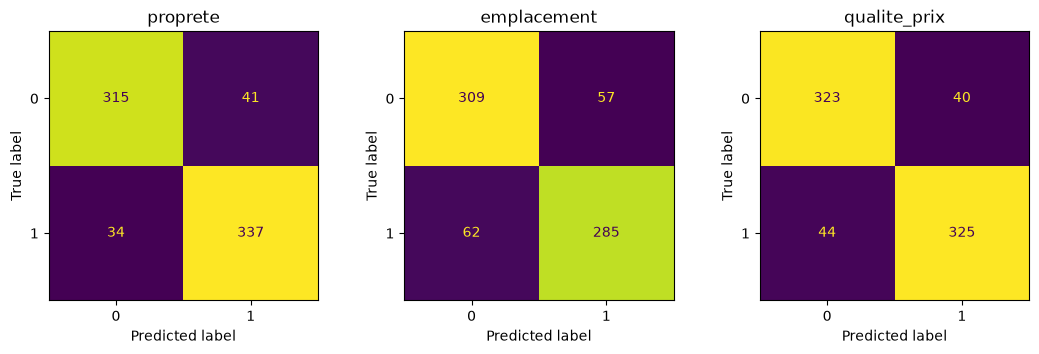

In [ ]:
modeles_finaux = {}
scores = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, categorie in zip(axes, categories):
    d = logements.dropna(subset=['y_' + categorie])

    # On choisi ici la meilleure version du texte trouver dans la cellule précédente, dans notre cas c'est text_stop.
    X, y = d['text_stop'], d['y_' + categorie].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75, stratify=y, random_state=42)

    modele = fo.pipeline(LinearSVC()).fit(X_train, y_train)
    y_pred = modele.predict(X_test)

    modeles_finaux[categorie] = modele
    scores[categorie] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, average='macro'),
        'recall': recall_score(y_test, y_pred, average='macro'),
        'f1': f1_score(y_test, y_pred, average='macro'),
    }
    
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
    ax.set_title(categorie)

display(pd.DataFrame(scores).T.round(3))
plt.show()

## 6. Mots les plus associés à chaque classe

Les coefficients du SVM linéaire indiquent les termes qui poussent vers chaque classe : un coefficient positif pousse vers "mieux noté", un coefficient négatif vers "moins bien noté" (même lecture que les coefficients de la régression logistique au TD5).
On vérifie ainsi que le modèle s’appuie sur des mots qui parlent vraiment de l’aspect étudié.

In [15]:
pd.concat({categorie: fo.mots_associes(modele) for categorie, modele in modeles_finaux.items()}, axis=1)

proprete                  emplacement                     \
   moins bien noté   mieux noté moins bien noté         mieux noté   
0              bon       propre             bon             situer   
1             mais  tres propre            gare         idealement   
2           situer         hote            mais        emplacement   
3      bien situer      decorer             peu             placer   
4              peu         tres             bus          tres bien   
5             bien   impeccable        agreable  idealement situer   
6             prix      accueil          passer       plein centre   
7           menage         gout        conforme              plein   
8          rapport      revenir          propre        bien situer   
9             sale      parfait        pratique        bien placer   
10           odeur    hote hote           photo            parfait   
11          placer  recommander         capucin           chartron   
12        pratique    excellent          maison         restaurant   
13           sympa         neuf          marche              calme   
14        arranger  accueillant    correspondre            revenir   

      qualite_prix               
   moins bien noté   mieux noté  
0             mais         hote  
1              peu  recommander  
2              bon      decorer  
3           situer      revenir  
4      bien situer    excellent  
5             bien  accueillant  
6         conforme         tres  
7            bemol      plaisir  
8          jacuzzi  confortable  
9         probleme         gout  
10          menage      parfait  
11       cependant  tres propre  
12           odeur   chaleureux  
13         dommage      accueil  
14         bruyant        super

## 7. Sauvegarde des résultats

In [13]:
Path('../resultats').mkdir(exist_ok=True)
comparaison.to_csv('../resultats/comparaison_modeles.csv')
ablation.to_csv('../resultats/ablation.csv')